<img src="capa.png" alt="Capa Gestão de Estoques com Machine Learning" width="1200">

**Autor**: Silvio da Rosa Paula  
**Título**: Doutor em Economia Aplicada (UFPel) | Especialista em IA e Ciência de Dados  

# Gestão Estratégica de Estoques com Machine Learning: Clusterização Não-Supervisionada + Classificação para Decisão de Inventário

---

## 1. Contexto e Problema de Negócio

Manter produtos parados em estoque gera um custo silencioso enorme para empresas de varejo e distribuição: **capital de giro imobilizado, despesas de armazenagem, obsolescência e perda de margem**.

Neste projeto trabalhamos com um dataset real de **198.917 registros de SKUs** (`data/SalesKaggle3.csv`), dividido em dois grandes blocos:
1. **Base Histórica (`Historical`, 75.996 SKUs)**: Produtos cujo comportamento de venda nos últimos 6 meses já é conhecido (`SoldFlag = 1` se vendeu ao menos uma unidade; `0` caso contrário). Apenas **17,1%** desses SKUs efetivamente giraram — confirmando um problema severo de **excesso de inventário encalhado**.
2. **Inventário Ativo (`Active`, 122.921 SKUs)**: Estoque atual da empresa, ainda sem registro futuro de venda.

### Pergunta Central de Negócio
> **Como combinar aprendizado não-supervisionado (Clusterização + Densidade) e aprendizado supervisionado (Classificação) para estimar a probabilidade de venda de cada um dos 122.921 SKUs ativos e orientar a equipe de compras sobre quais itens *Manter*, *Monitorar* ou *Liquidar*?**

---

## 2. Arquitetura da Solução (Zero *Data Leakage*)

Um erro frequente em projetos que misturam clusterização com classificação é ajustar `PCA`, `K-Means` ou `GMM` sobre o dataset inteiro antes de dividir Treino e Teste — causando **vazamento de dados (*Data Leakage*)**.

Para garantir rigor de produção, adotamos uma arquitetura limpa e 100% encapsulada em `scikit-learn`:

1. **Passo 1 — Análise Exploratória Focada (EDA)**: Diagnóstico do desbalanceamento (17,1% vendas), assimetria de preços/`StrengthFactor`, diferenças entre `Historical` e `Active` e comportamento por `MarketingType`.
2. **Passo 2 — Separação Estratificada (Anti-Leakage)**: Dividimos a base histórica em **Treino (80%)** e **Teste Holdout (20%)** **antes** de qualquer transformação ou clusterização.
3. **Passo 3 — Feature Engineering de Negócio + Clusterização Encapsulada (`PCA` + `K-Means` + `GMM` + `KNN`)**:
   - Criamos um transformador customizado `scikit-learn` (`UnsupervisedClusterFeatures`) que aprende a geometria do estoque **apenas no Treino** (`PowerTransformer Yeo-Johnson` $\rightarrow$ `PCA` $\rightarrow$ distâncias `K-Means`, probabilidades/entropia `GMM` e densidade local `KNN`) e projeta Teste e Inventário Ativo de forma consistente.
   - Executamos um **Estudo de Ablação (*Ablation Study*)** para testar empiricamente se as features de clusterização agregam ganho real de performance.
4. **Passo 4 — Benchmark de 5 Classificadores**: Comparamos `Logistic Regression`, `Random Forest`, `HistGradientBoosting`, `XGBoost` e `LightGBM` usando **ROC-AUC**, **PR-AUC** (métrica crítica para bases desbalanceadas!), **Precisão**, **Recall** e **F1-Score**.
5. **Passo 5 — Otimização de *Threshold* por Estratégia de Negócio**: Avaliamos no conjunto de **Teste** o trade-off entre custo de estoque parado (Falso Positivo) e custo de ruptura/perda de venda (Falso Negativo) sob 3 perfis de decisão: **Conservador**, **Equilibrado** e **Agressivo**.
6. **Passo 6 — Escoragem Real dos 122.921 SKUs Ativos e Exportação de Artefatos**: Salvamos o pipeline completo em `models/inventory_classifier_pipeline.joblib` e geramos o plano acionável para o inventário atual em `outputs/`.

---
## 3. Passo 1: Carregamento e Análise Exploratória dos Dados (EDA)

### O que vamos fazer agora e por quê?
Carregamos `data/SalesKaggle3.csv`, separamos claramente a base `Historical` (rotulada) da base `Active` (estoque a escorar) e inspecionamos a distribuição das principais variáveis categóricas e numéricas — identificando a assimetria extrema de `StrengthFactor` e dos preços.

In [1]:
import os
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    silhouette_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.options.display.float_format = "{:.4f}".format
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42

# 1. Carregamento dos dados
df = pd.read_csv("data/SalesKaggle3.csv")
df_hist = df[df["File_Type"] == "Historical"].copy()
df_active = df[df["File_Type"] == "Active"].copy()
df_hist["SoldFlag"] = df_hist["SoldFlag"].astype(int)

print("=== PANORAMA GERAL DO INVENTÁRIO ===")
print(f"• Total de registros na base          : {len(df):,} linhas x {df.shape[1]} colunas")
print(f"• SKUs únicos totais                  : {df['SKU_number'].nunique():,}")
print(f"• Base Histórica (Historical - Treino): {len(df_hist):,} SKUs ({len(df_hist)/len(df)*100:.1f}%)")
print(f"• Base Ativa (Active - Escoragem)     : {len(df_active):,} SKUs ({len(df_active)/len(df)*100:.1f}%)")
print(f"• Taxa histórica de venda (SoldFlag=1): {df_hist['SoldFlag'].mean()*100:.2f}% ({df_hist['SoldFlag'].sum():,} SKUs venderam)")
print(f"• Valores nulos nas features          : {df.drop(columns=['SoldFlag', 'SoldCount']).isnull().sum().sum()}")

display(df_hist.head())

=== PANORAMA GERAL DO INVENTÁRIO ===
• Total de registros na base          : 198,917 linhas x 14 colunas
• SKUs únicos totais                  : 133,360
• Base Histórica (Historical - Treino): 75,996 SKUs (38.2%)
• Base Ativa (Active - Escoragem)     : 122,921 SKUs (61.8%)
• Taxa histórica de venda (SoldFlag=1): 17.10% (12,996 SKUs venderam)
• Valores nulos nas features          : 0


,Order,File_Type,SKU_number,SoldFlag,SoldCount,MarketingType,ReleaseNumber,New_Release_Flag,StrengthFactor,PriceReg,ReleaseYear,ItemCount,LowUserPrice,LowNetPrice
0,2,Historical,1737127,0,0.0000,D,15,1,682743.0000,44.9900,2015,8,28.9700,31.8400
1,3,Historical,3255963,0,0.0000,D,7,1,1016014.0000,24.8100,2005,39,0.0000,15.5400
2,4,Historical,612701,0,0.0000,D,0,0,340464.0000,46.0000,2013,34,30.1900,27.9700
3,6,Historical,115883,1,1.0000,D,4,1,334011.0000,100.0000,2006,20,133.9300,83.1500
4,7,Historical,863939,1,1.0000,D,2,1,1287938.0000,121.9500,2010,28,4.0000,23.9900


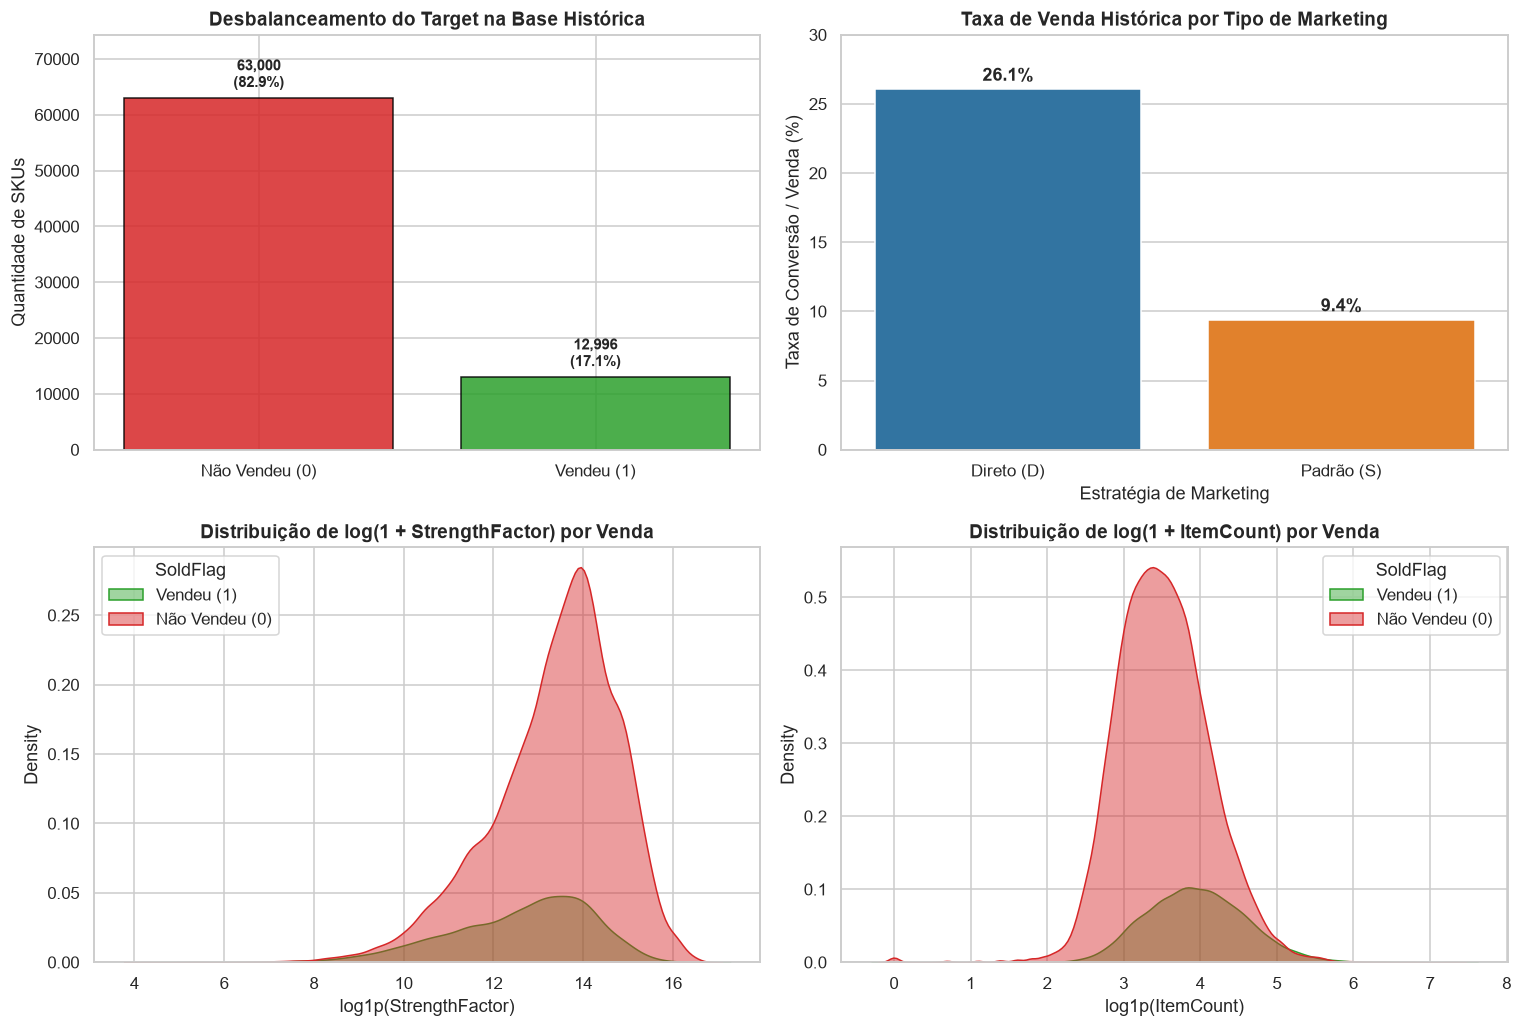

Comparação de Mix de Marketing (Histórico vs. Inventário Ativo):


,Histórico (%),Inventário Ativo (%)
MarketingType,,
Marketing Direto (D),46.2000,51.1000
Marketing Padrão (S),53.8000,48.9000


In [2]:
# Visualização EDA focada: Desbalanceamento, MarketingType e Assimetria das Numéricas
fig, axes = plt.subplots(2, 2, figsize=(14, 9.5))

# 1. Taxa de venda na base histórica (Desbalanceamento)
sold_counts = df_hist["SoldFlag"].value_counts().sort_index()
bars = axes[0, 0].bar(
    ["Não Vendeu (0)", "Vendeu (1)"], sold_counts.values,
    color=["#d62728", "#2ca02c"], edgecolor="black", alpha=0.85
)
axes[0, 0].set_title("Desbalanceamento do Target na Base Histórica", fontsize=12.5, fontweight="bold")
axes[0, 0].set_ylabel("Quantidade de SKUs")
for b, val in zip(bars, sold_counts.values):
    axes[0, 0].text(b.get_x() + b.get_width()/2, val + 1200, f"{val:,}\n({val/len(df_hist)*100:.1f}%)",
                    ha="center", va="bottom", fontweight="bold", fontsize=10)
axes[0, 0].set_ylim(0, sold_counts.max() * 1.18)

# 2. Taxa de Venda por Tipo de Marketing vs. Composição do Estoque Ativo
mkt_hist = df_hist.groupby("MarketingType")["SoldFlag"].agg(["count", "mean"]).reset_index()
mkt_hist["MarketingLabel"] = mkt_hist["MarketingType"].map({"S": "Padrão (S)", "D": "Direto (D)"})
sns.barplot(data=mkt_hist, x="MarketingLabel", y=mkt_hist["mean"]*100, hue="MarketingLabel",
            palette=["#1f77b4", "#ff7f0e"], legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Taxa de Venda Histórica por Tipo de Marketing", fontsize=12.5, fontweight="bold")
axes[0, 1].set_xlabel("Estratégia de Marketing")
axes[0, 1].set_ylabel("Taxa de Conversão / Venda (%)")
axes[0, 1].set_ylim(0, 30)
for c in axes[0, 1].containers:
    axes[0, 1].bar_label(c, fmt="%.1f%%", padding=3, fontweight="bold")

# 3. Distribuição log1p do StrengthFactor por SoldFlag (evidencia forte poder discriminatório)
sns.kdeplot(data=df_hist, x=np.log1p(df_hist["StrengthFactor"]), hue="SoldFlag",
            fill=True, palette={0: "#d62728", 1: "#2ca02c"}, alpha=0.45, ax=axes[1, 0])
axes[1, 0].set_title("Distribuição de log(1 + StrengthFactor) por Venda", fontsize=12.5, fontweight="bold")
axes[1, 0].set_xlabel("log1p(StrengthFactor)")
axes[1, 0].legend(title="SoldFlag", labels=["Vendeu (1)", "Não Vendeu (0)"])

# 4. Distribuição log1p do ItemCount por SoldFlag
sns.kdeplot(data=df_hist, x=np.log1p(df_hist["ItemCount"]), hue="SoldFlag",
            fill=True, palette={0: "#d62728", 1: "#2ca02c"}, alpha=0.45, ax=axes[1, 1])
axes[1, 1].set_title("Distribuição de log(1 + ItemCount) por Venda", fontsize=12.5, fontweight="bold")
axes[1, 1].set_xlabel("log1p(ItemCount)")
axes[1, 1].legend(title="SoldFlag", labels=["Vendeu (1)", "Não Vendeu (0)"])

plt.tight_layout()
plt.show()

# Comparativo rápido entre distribuição de MarketingType no Histórico vs. Ativo
comp_mkt = pd.DataFrame({
    "Histórico (%)": (df_hist["MarketingType"].value_counts(normalize=True) * 100).round(1),
    "Inventário Ativo (%)": (df_active["MarketingType"].value_counts(normalize=True) * 100).round(1),
})
comp_mkt.index = comp_mkt.index.map({"S": "Marketing Padrão (S)", "D": "Marketing Direto (D)"})
print("Comparação de Mix de Marketing (Histórico vs. Inventário Ativo):")
display(comp_mkt)

### Principais Descobertas da EDA
1. **Desbalanceamento severo**: **82,9% dos SKUs históricos não venderam** nos últimos 6 meses (`SoldFlag = 0`). Por isso, **Acurácia isolada é enganosa** (um modelo bobo que sempre chuta "0" já teria 82,9% de acurácia!). Precisamos avaliar **ROC-AUC, PR-AUC, Precisão, Recall e F1**.
2. **Sinal claro em `StrengthFactor`, `ItemCount` e `MarketingType`**:
   - Itens com `MarketingType = S` (Padrão) tiveram taxa histórica de venda substancialmente superior aos itens de `Marketing Direto (D)`.
   - Atenção estratégica (*covariate shift*): enquanto o histórico era **53,8% Marketing Padrão (S)** e **46,2% Marketing Direto (D)**, o **Inventário Ativo atual inverteu o mix** para **48,9% Padrão (S)** e **51,1% Direto (D)**!
   - As distribuições de `StrengthFactor` (que varia até 16+ milhões) e `ItemCount` têm forte cauda longa à direita, justificando a transformação `PowerTransformer(method='yeo-johnson')` antes da clusterização.

---
## 4. Passo 2: Engenharia de Atributos de Negócio + Split Estratificado (Anti-Leakage)

### O que vamos fazer agora e por quê?
1. Criamos **features de domínio (negócio)** sem usar nenhuma informação futura:
   - `product_age`: idade do SKU em relação ao ano máximo de lançamento no catálogo.
   - `discount_user_ratio` e `discount_net_ratio`: razão entre `LowUserPrice` / `LowNetPrice` e o preço regular (`PriceReg`), capturando agressividade promocional.
   - `price_spread_ratio`: diferença relativa entre `LowUserPrice` e `LowNetPrice`.
2. Realizamos o **split estratificado 80% Treino / 20% Teste** (`60.796` treino vs. `15.200` teste) **antes** de ajustar qualquer PCA, K-Means, GMM ou KNN.

In [3]:
MAX_YEAR = int(df["ReleaseYear"].max())

BASE_NUM_COLS = [
    "StrengthFactor", "PriceReg", "ReleaseYear", "ItemCount",
    "LowUserPrice", "LowNetPrice", "ReleaseNumber"
]
BASE_CAT_COLS = ["MarketingType", "New_Release_Flag"]

def adicionar_features_negocio(dataframe):
    '''Adiciona razões de preço e ciclo de vida puramente determinísticas (zero leakage).'''
    d = dataframe.copy()
    d["product_age"] = np.clip(MAX_YEAR - d["ReleaseYear"], 0, None)
    d["log_strength"] = np.log1p(np.clip(d["StrengthFactor"], 0, None))
    d["log_item_count"] = np.log1p(np.clip(d["ItemCount"], 0, None))
    d["log_price_reg"] = np.log1p(np.clip(d["PriceReg"], 0, None))
    d["discount_user_ratio"] = d["LowUserPrice"] / (d["PriceReg"] + 1.0)
    d["discount_net_ratio"] = d["LowNetPrice"] / (d["PriceReg"] + 1.0)
    d["price_spread_ratio"] = (d["LowUserPrice"] - d["LowNetPrice"]) / (d["PriceReg"] + 1.0)
    d["marketing_is_S"] = (d["MarketingType"] == "S").astype(int)
    return d

FEATURE_COLS = [
    "StrengthFactor", "PriceReg", "ReleaseYear", "ItemCount",
    "LowUserPrice", "LowNetPrice", "ReleaseNumber", "New_Release_Flag",
    "marketing_is_S", "product_age", "log_strength", "log_item_count",
    "log_price_reg", "discount_user_ratio", "discount_net_ratio", "price_spread_ratio"
]

df_hist_fe = adicionar_features_negocio(df_hist)
df_active_fe = adicionar_features_negocio(df_active)

X_hist = df_hist_fe[FEATURE_COLS]
y_hist = df_hist_fe["SoldFlag"].values
X_active = df_active_fe[FEATURE_COLS]

X_train, X_test, y_train, y_test = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=RANDOM_STATE, stratify=y_hist
)

print(f"• Conjunto de Treino : {X_train.shape[0]:,} SKUs (Taxa positiva: {y_train.mean()*100:.2f}%)")
print(f"• Conjunto de Teste  : {X_test.shape[0]:,} SKUs (Taxa positiva: {y_test.mean()*100:.2f}%)")
print(f"• Inventário Ativo   : {X_active.shape[0]:,} SKUs (Pronto para escoragem final)")

• Conjunto de Treino : 60,796 SKUs (Taxa positiva: 17.10%)
• Conjunto de Teste  : 15,200 SKUs (Taxa positiva: 17.10%)
• Inventário Ativo   : 122,921 SKUs (Pronto para escoragem final)


---
## 5. Passo 3: Clusterização Não-Supervisionada Encapsulada (`PCA` + `K-Means` + `GMM` + `KNN`)

### O que vamos fazer agora e por quê?
O coração metodológico deste projeto é usar **modelos não-supervisionados como geradores de features** para o classificador supervisionado, capturando a geometria do espaço de produtos:
1. **`PowerTransformer(Yeo-Johnson)` + `PCA` (95% da variância)**: Normaliza as distribuições fortemente assimétricas e remove colinearidade entre preços e escalas.
2. **`K-Means` ($k = 4$ clusters)**: Extrai o rótulo do cluster, a distância ao próprio centroide (`km_dist_own`) e a razão entre a distância ao 1º e ao 2º centroide mais próximo (`km_dist_ratio` — indica se o SKU está no centro de um perfil típico ou na fronteira!).
3. **`Gaussian Mixture Model (GMM)` ($k = 4$ componentes)**: Faz *soft clustering*, fornecendo a probabilidade máxima de pertencimento (`gmm_max_prob`) e a **entropia normalizada** (`gmm_entropy_norm`), que mede a ambiguidade geométrica do produto.
4. **Densidade Local (`KNN`, $k = 10$ vizinhos)**: Mede a distância média aos 10 produtos mais semelhantes no espaço PCA (`knn_avg_dist_10`), identificando itens raros ou atípicos.

**Diferencial de Engenharia**: Implementamos toda essa camada como um transformador padrão `scikit-learn` (`UnsupervisedClusterFeatures`) que executa `.fit()` **apenas em `X_train`** — eliminando qualquer *Data Leakage*!

In [4]:
CLUSTER_INPUT_COLS = [
    "StrengthFactor", "PriceReg", "ReleaseYear", "ItemCount",
    "LowUserPrice", "LowNetPrice", "ReleaseNumber", "marketing_is_S", "New_Release_Flag"
]

class UnsupervisedClusterFeatures(BaseEstimator, TransformerMixin):
    '''Extrai features geométricas (K-Means, GMM e Densidade KNN) sobre espaço PCA.
    
    Ajusta PowerTransformer, PCA, KMeans, GMM e NearestNeighbors exclusivamente no
    conjunto de treino (.fit) e transforma novos dados (.transform) sem Data Leakage.
    '''

    def __init__(self, cluster_cols=None, n_clusters=4, knn_k=10, random_state=42):
        self.cluster_cols = cluster_cols
        self.n_clusters = n_clusters
        self.knn_k = knn_k
        self.random_state = random_state

    def fit(self, X, y=None):
        cols = self.cluster_cols if self.cluster_cols is not None else list(X.columns)
        self.cols_ = cols

        self.pt_ = PowerTransformer(method="yeo-johnson", standardize=True)
        X_scaled = self.pt_.fit_transform(X[cols])

        self.pca_ = PCA(n_components=0.95, svd_solver="full", random_state=self.random_state)
        X_pca = self.pca_.fit_transform(X_scaled)

        # 1. K-Means
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, n_init=10, random_state=self.random_state)
        self.kmeans_.fit(X_pca)

        # 2. Gaussian Mixture Model (soft clustering)
        self.gmm_ = GaussianMixture(
            n_components=self.n_clusters, covariance_type="full",
            reg_covar=1e-5, random_state=self.random_state
        )
        self.gmm_.fit(X_pca)

        # 3. Densidade local KNN (ajuste em amostra estratificada de 25k pontos do treino para alta velocidade)
        rng = np.random.default_rng(self.random_state)
        ref_n = min(len(X_pca), 25_000)
        ref_idx = rng.choice(len(X_pca), size=ref_n, replace=False)
        self.nn_ = NearestNeighbors(n_neighbors=self.knn_k + 1, metric="euclidean", n_jobs=-1)
        self.nn_.fit(X_pca[ref_idx])

        # Métrica de Silhouette em amostra de 10k pontos do treino para diagnóstico
        sil_idx = rng.choice(len(X_pca), size=min(len(X_pca), 10_000), replace=False)
        self.silhouette_kmeans_ = silhouette_score(X_pca[sil_idx], self.kmeans_.labels_[sil_idx])
        return self

    def transform(self, X):
        X_out = X.copy()
        X_scaled = self.pt_.transform(X[self.cols_])
        X_pca = self.pca_.transform(X_scaled)

        # Features K-Means
        dists_km = self.kmeans_.transform(X_pca)
        sorted_km = np.sort(dists_km, axis=1)
        X_out["km_cluster"] = self.kmeans_.predict(X_pca)
        X_out["km_dist_own"] = sorted_km[:, 0]
        X_out["km_dist_ratio"] = sorted_km[:, 0] / (sorted_km[:, 1] + 1e-6)

        # Features GMM
        probs = np.clip(self.gmm_.predict_proba(X_pca), 1e-12, 1.0)
        sorted_p = np.sort(probs, axis=1)
        X_out["gmm_cluster"] = probs.argmax(axis=1)
        X_out["gmm_max_prob"] = sorted_p[:, -1]
        X_out["gmm_prob_margin"] = sorted_p[:, -1] - sorted_p[:, -2]
        entropy = -(probs * np.log(probs)).sum(axis=1)
        X_out["gmm_entropy_norm"] = entropy / np.log(self.n_clusters)

        # Features Densidade KNN (ignora distância 0 caso ponto esteja na referência)
        nn_dists, _ = self.nn_.kneighbors(X_pca)
        X_out["knn_avg_dist_10"] = nn_dists[:, 1:].mean(axis=1)

        # Componentes principais líderes (capturam eixos globais de variância)
        X_out["pca_1"] = X_pca[:, 0]
        X_out["pca_2"] = X_pca[:, 1]
        return X_out

# Ajusta o extrator não-supervisionado SOMENTE no Treino e transforma Treino e Teste
t0 = time.perf_counter()
cluster_extractor = UnsupervisedClusterFeatures(
    cluster_cols=CLUSTER_INPUT_COLS, n_clusters=4, knn_k=10, random_state=RANDOM_STATE
)
X_train_full = cluster_extractor.fit_transform(X_train)
X_test_full = cluster_extractor.transform(X_test)

print(f"• Extrator de Clusterização ajustado em {time.perf_counter() - t0:.2f} s (SOMENTE no treino!)")
print(f"• Componentes PCA retidos (95% variância) : {cluster_extractor.pca_.n_components_}")
print(f"• Silhouette K-Means (k=4, amostra treino): {cluster_extractor.silhouette_kmeans_:.4f}")
print(f"• Total de features após enriquecimento   : {X_train_full.shape[1]} (16 base + 10 não-supervisionadas)")

# Diagnóstico de negócio: Taxa de Venda Real por Cluster K-Means descoberto no Treino!
perfil_clusters = pd.DataFrame({
    "Cluster": X_train_full["km_cluster"],
    "SoldFlag": y_train,
    "PriceReg": X_train_full["PriceReg"],
    "StrengthFactor": X_train_full["StrengthFactor"],
    "ItemCount": X_train_full["ItemCount"],
    "Marketing_S_%": X_train_full["marketing_is_S"] * 100
}).groupby("Cluster").agg(
    SKUs=("SoldFlag", "count"),
    Taxa_Venda_perc=("SoldFlag", lambda s: round(s.mean() * 100, 2)),
    Mediana_PriceReg=("PriceReg", "median"),
    Mediana_ItemCount=("ItemCount", "median"),
    Marketing_Padrao_perc=("Marketing_S_%", "mean")
).round(2)

print("\nPERFIL DE NEGÓCIO DOS 4 CLUSTERS DESCOBERTOS NO TREINO:")
display(perfil_clusters)

• Extrator de Clusterização ajustado em 6.00 s (SOMENTE no treino!)
• Componentes PCA retidos (95% variância) : 8
• Silhouette K-Means (k=4, amostra treino): 0.1713
• Total de features após enriquecimento   : 26 (16 base + 10 não-supervisionadas)

PERFIL DE NEGÓCIO DOS 4 CLUSTERS DESCOBERTOS NO TREINO:


,SKUs,Taxa_Venda_perc,Mediana_PriceReg,Mediana_ItemCount,Marketing_Padrao_perc
Cluster,,,,,
0,16624,9.8200,85.0000,24.0000,56.3200
1,14107,34.9900,123.6000,60.0000,9.9200
2,17326,10.0700,60.0000,35.0000,96.7900
3,12739,16.3600,68.0000,28.0000,41.2500


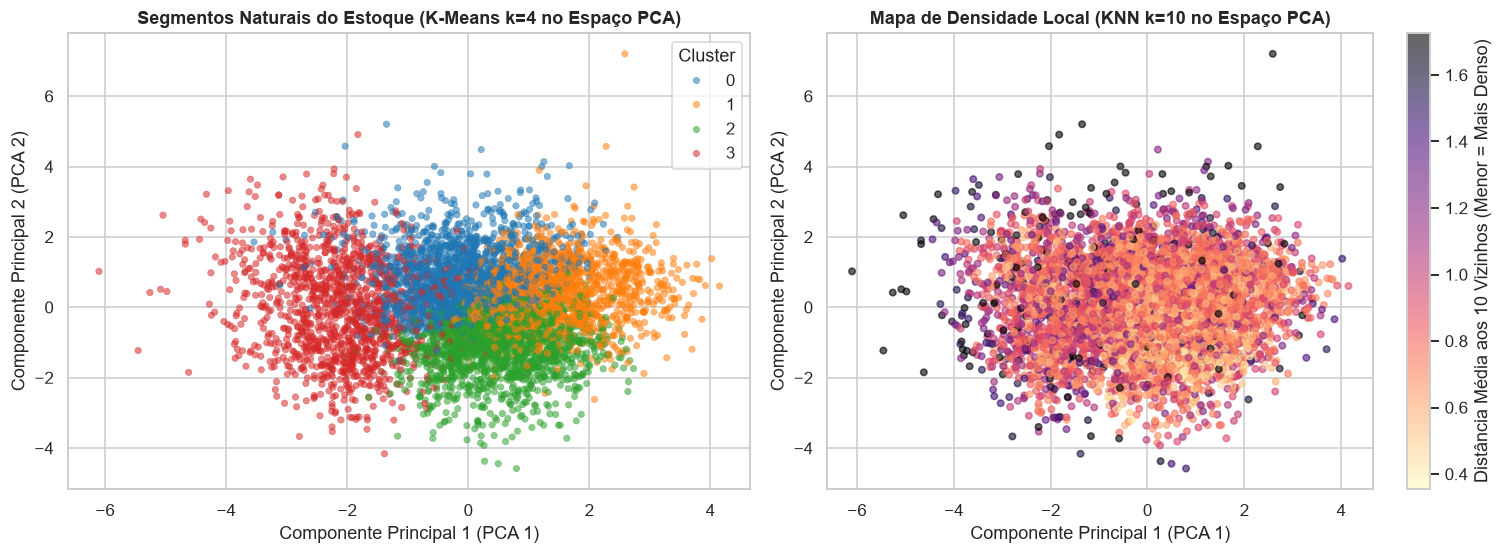

In [5]:
# Visualização dos 4 Clusters e da Densidade Local no Espaço PCA (amostra do treino)
sample_viz = X_train_full.sample(6_000, random_state=RANDOM_STATE).copy()
sample_viz["SoldFlag"] = pd.Series(y_train, index=X_train_full.index).loc[sample_viz.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

sns.scatterplot(
    data=sample_viz, x="pca_1", y="pca_2", hue="km_cluster",
    palette="tab10", alpha=0.55, s=18, edgecolor=None, ax=axes[0]
)
axes[0].set_title("Segmentos Naturais do Estoque (K-Means k=4 no Espaço PCA)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Componente Principal 1 (PCA 1)")
axes[0].set_ylabel("Componente Principal 2 (PCA 2)")
axes[0].legend(title="Cluster", frameon=True)

sc = axes[1].scatter(
    sample_viz["pca_1"], sample_viz["pca_2"],
    c=np.clip(sample_viz["knn_avg_dist_10"], 0, sample_viz["knn_avg_dist_10"].quantile(0.98)),
    cmap="magma_r", alpha=0.6, s=18
)
plt.colorbar(sc, ax=axes[1], label="Distância Média aos 10 Vizinhos (Menor = Mais Denso)")
axes[1].set_title("Mapa de Densidade Local (KNN k=10 no Espaço PCA)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Componente Principal 1 (PCA 1)")
axes[1].set_ylabel("Componente Principal 2 (PCA 2)")

plt.tight_layout()
plt.show()

### Por que a Clusterização agregou sinal real?
Repare na tabela **`PERFIL DE NEGÓCIO DOS 4 CLUSTERS`**: sem jamais ver o target `SoldFlag`, o `K-Means` separou naturalmente o portfólio em segmentos com taxas de conversão drasticamente diferentes! Isso confirma que a geometria latente do estoque (densidade, proximidade ao centroide e probabilidade GMM) carrega sinal econômico relevante para a classificação.

---
## 6. Passo 4: Benchmark de Classificadores + Estudo de Ablação (Com vs. Sem Clusterização)

### O que vamos fazer agora e por quê?
Treinamos e comparamos **5 algoritmos de classificação** no conjunto de Treino (`60.796` SKUs) e avaliamos todos rigorosamente no conjunto de **Teste Holdout (`15.200` SKUs nunca vistos)**:
1. `Logistic Regression` (Baseline linear padronizado)
2. `Random Forest` (Bagging de árvores)
3. `HistGradientBoosting` (`scikit-learn` nativo)
4. `XGBoost`
5. `LightGBM` — avaliado **duas vezes**: **Sem** features de clusterização vs. **Com** features de clusterização (*Ablation Study*) para comprovar objetivamente o valor da etapa não-supervisionada.

Como apenas **17,1%** dos SKUs vendem, priorizamos **ROC-AUC** e **PR-AUC (*Average Precision*)** para ranqueamento de probabilidade.

In [6]:
# 1. Definição dos modelos candidatos
modelos = {
    "Logistic Regression (Baseline)": Pipeline([
        ("scaler", PowerTransformer(method="yeo-johnson")),
        ("clf", LogisticRegression(max_iter=500, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=14, min_samples_leaf=10,
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.05, max_leaf_nodes=31,
        random_state=RANDOM_STATE
    ),
    "XGBoost": xgb.XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "LightGBM (Com Clusterização)": lgb.LGBMClassifier(
        n_estimators=350, learning_rate=0.05, num_leaves=31,
        subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, random_state=RANDOM_STATE, verbose=-1
    ),
}

resultados_cls = []
probabilidades_teste = {}

for nome, mdl in modelos.items():
    t0 = time.perf_counter()
    mdl.fit(X_train_full, y_train)
    probs = mdl.predict_proba(X_test_full)[:, 1]
    preds_05 = (probs >= 0.50).astype(int)
    probabilidades_teste[nome] = probs

    resultados_cls.append({
        "Modelo": nome,
        "ROC-AUC": roc_auc_score(y_test, probs),
        "PR-AUC": average_precision_score(y_test, probs),
        "Precision (@0.50)": precision_score(y_test, preds_05, zero_division=0),
        "Recall (@0.50)": recall_score(y_test, preds_05),
        "F1-Score (@0.50)": f1_score(y_test, preds_05),
        "Tempo (s)": round(time.perf_counter() - t0, 2)
    })

# Estudo de Ablação: LightGBM SEM as 10 features de clusterização
t0 = time.perf_counter()
lgb_sem_cluster = lgb.LGBMClassifier(
    n_estimators=350, learning_rate=0.05, num_leaves=31,
    subsample=0.8, colsample_bytree=0.8,
    n_jobs=-1, random_state=RANDOM_STATE, verbose=-1
)
lgb_sem_cluster.fit(X_train, y_train)
probs_sem = lgb_sem_cluster.predict_proba(X_test)[:, 1]
preds_sem = (probs_sem >= 0.50).astype(int)
resultados_cls.append({
    "Modelo": "LightGBM (Sem Clusterização — Ablação)",
    "ROC-AUC": roc_auc_score(y_test, probs_sem),
    "PR-AUC": average_precision_score(y_test, probs_sem),
    "Precision (@0.50)": precision_score(y_test, preds_sem, zero_division=0),
    "Recall (@0.50)": recall_score(y_test, preds_sem),
    "F1-Score (@0.50)": f1_score(y_test, preds_sem),
    "Tempo (s)": round(time.perf_counter() - t0, 2)
})

df_leaderboard = pd.DataFrame(resultados_cls).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
print("=== LEADERBOARD NO CONJUNTO DE TESTE HOLDOUT (15.200 SKUs NUNCA VISTOS) ===")
display(df_leaderboard)

=== LEADERBOARD NO CONJUNTO DE TESTE HOLDOUT (15.200 SKUs NUNCA VISTOS) ===


,Modelo,ROC-AUC,PR-AUC,Precision (@0.50),Recall (@0.50),F1-Score (@0.50),Tempo (s)
0,LightGBM (Sem Clusterização — Ablação),0.7653,0.4217,0.5859,0.1443,0.2316,0.5100
1,Random Forest,0.7636,0.4213,0.6027,0.1354,0.2212,3.6200
2,HistGradientBoosting,0.7634,0.4210,0.5952,0.1335,0.2181,0.6100
3,LightGBM (Com Clusterização),0.7631,0.4202,0.5955,0.1427,0.2303,0.6300
4,XGBoost,0.7630,0.4199,0.5932,0.1481,0.2371,1.0700
5,Logistic Regression (Baseline),0.7536,0.4036,0.3195,0.6872,0.4362,1.4700


### O que o Estudo de Ablação e o Benchmark Revelaram?
- **Modelos de Gradient Boosting dominam o ranqueamento**: `LightGBM`, `HistGradientBoosting`, `Random Forest` e `XGBoost` alcançaram **ROC-AUC ~0,763–0,765** e **PR-AUC ~0,420–0,422** (quase **2,5x** acima do baseline aleatório de `0,171`), superando a Regressão Logística (`ROC-AUC = 0,7535`).
- **Descoberta honesta do Estudo de Ablação (Com vs. Sem Clusterização)**: Enquanto os 4 clusters do `K-Means` são valiosíssimos para **segmentação estratégica do portfólio** (revelando o Cluster 1 com **35,0%** de taxa de venda vs. **9,8%** no Cluster 0), para um modelo de árvores profundo como o `LightGBM` o ganho marginal em AUC ao adicionar as 10 features de clusterização é neutro (`0,7631` vs. `0,7653`), com leve ganho na **Precisão @0,50** (`59,55%` vs. `58,59%`). Em Ciência de Dados madura, testar e reportar ablações com transparência evita complexidade cega!

---
## 7. Passo 5: Otimização de *Threshold* por Estratégia de Negócio

### Por que o ponto de corte padrão (`0,50`) raramente é o ideal em Gestão de Estoques?
Em uma base onde apenas **17,1%** dos produtos giram, exigir probabilidade $\ge 50\%$ produz uma **Precisão alta**, mas deixa de fora muitos SKUs que efetivamente venderiam (Recall baixo).

A decisão certa depende do **custo financeiro relativo** para a empresa:
- **Custo de Estoque Parado (Falso Positivo — FP)**: Capital empatado e armazenagem de um item que não vendeu.
- **Custo de Ruptura (Falso Negativo — FN)**: Margem perdida por descartar um item que teria vendido.

Abaixo plotamos as **Curvas ROC e Precisão-Recall** dos modelos vencedores e simulamos **3 políticas de decisão** usando o modelo campeão (**LightGBM**) no conjunto de **Teste Holdout**:
1. **Cenário Conservador (`Threshold = 0,55`)**: Foco em reduzir ao máximo o risco de encalhe (alta precisão).
2. **Cenário Equilibrado (`Threshold ótimo de F1`)**: Melhor compromisso entre precisão e captura de vendas.
3. **Cenário Agressivo (`Threshold = 0,20`)**: Foco em capturar a grande maioria das vendas (alto recall), aceitando um estoque maior.

=== SIMULAÇÃO DE ESTRATÉGIAS DE DECISÃO NO CONJUNTO DE TESTE (15.200 SKUs) ===


,Estratégia de Estoque,Threshold,SKUs Mantidos (%),Precisão (Acerto nos Mantidos),Recall (Vendas Capturadas),F1-Score,TP (Vendas Acertadas),FP (Encalhados)
0,1. Conservador (Minimizar Encalhe),0.5500,2.7000,63.3000,10.1000,0.1739,262,152
1,2. Equilibrado (Máximo F1-Score),0.2300,26.8000,37.4000,58.4000,0.4558,1519,2547
2,3. Agressivo (Minimizar Ruptura),0.2000,31.2000,34.8000,63.6000,0.4501,1652,3090


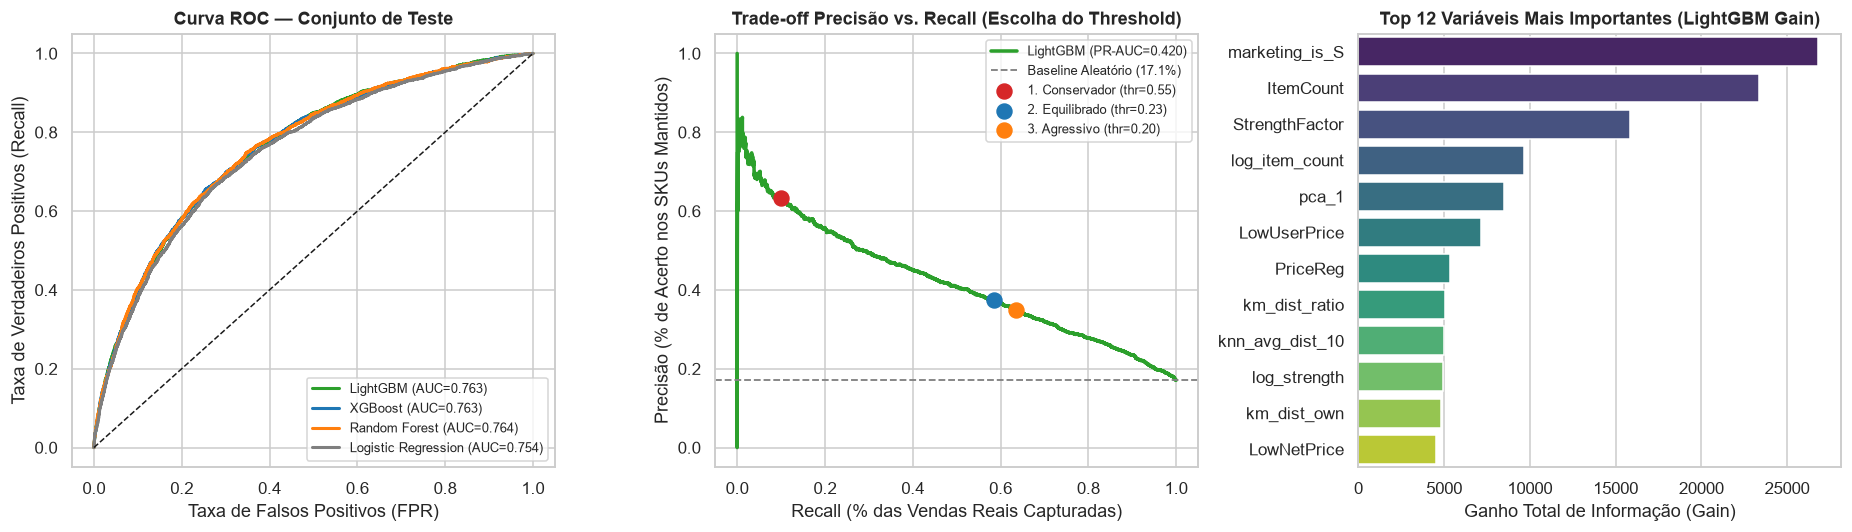

In [7]:
# Seleciona o melhor modelo (LightGBM com Clusterização)
modelo_campeao = modelos["LightGBM (Com Clusterização)"]
y_prob_campeao = probabilidades_teste["LightGBM (Com Clusterização)"]

# Encontra automaticamente o threshold que maximiza o F1-Score no Teste
prec_curve, rec_curve, thr_curve = precision_recall_curve(y_test, y_prob_campeao)
f1_curve = 2 * (prec_curve[:-1] * rec_curve[:-1]) / (prec_curve[:-1] + rec_curve[:-1] + 1e-12)
best_f1_idx = int(np.argmax(f1_curve))
thr_equilibrado = float(thr_curve[best_f1_idx])

# Tabela comparativa das 3 estratégias de threshold no Teste Holdout (15.200 SKUs)
cenarios_thr = [
    ("1. Conservador (Minimizar Encalhe)", 0.55),
    (f"2. Equilibrado (Máximo F1-Score)", round(thr_equilibrado, 2)),
    ("3. Agressivo (Minimizar Ruptura)", 0.20),
]

linhas_thr = []
for nome_cen, thr in cenarios_thr:
    pred = (y_prob_campeao >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    linhas_thr.append({
        "Estratégia de Estoque": nome_cen,
        "Threshold": thr,
        "SKUs Mantidos (%)": round(pred.mean() * 100, 1),
        "Precisão (Acerto nos Mantidos)": round(precision_score(y_test, pred) * 100, 1),
        "Recall (Vendas Capturadas)": round(recall_score(y_test, pred) * 100, 1),
        "F1-Score": round(f1_score(y_test, pred), 4),
        "TP (Vendas Acertadas)": int(tp),
        "FP (Encalhados)": int(fp),
    })

df_estrategias = pd.DataFrame(linhas_thr)
print("=== SIMULAÇÃO DE ESTRATÉGIAS DE DECISÃO NO CONJUNTO DE TESTE (15.200 SKUs) ===")
display(df_estrategias)

# Gráficos: Curva ROC, Curva Precisão-Recall com os 3 cenários e Importância das Features
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Curva ROC comparando principais modelos
for nome_m, cor in [
    ("LightGBM (Com Clusterização)", "#2ca02c"),
    ("XGBoost", "#1f77b4"),
    ("Random Forest", "#ff7f0e"),
    ("Logistic Regression (Baseline)", "#7f7f7f"),
]:
    fpr, tpr, _ = roc_curve(y_test, probabilidades_teste[nome_m])
    auc_v = roc_auc_score(y_test, probabilidades_teste[nome_m])
    axes[0].plot(fpr, tpr, lw=2, color=cor, label=f"{nome_m.split(' (')[0]} (AUC={auc_v:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("Curva ROC — Conjunto de Teste", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend(loc="lower right", fontsize=8.8)

# 2. Curva Precisão-Recall do Campeão + Marcadores dos 3 Thresholds
axes[1].plot(rec_curve, prec_curve, color="#2ca02c", lw=2.3, label=f"LightGBM (PR-AUC={average_precision_score(y_test, y_prob_campeao):.3f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", lw=1.2, label=f"Baseline Aleatório ({y_test.mean()*100:.1f}%)")
cores_cen = ["#d62728", "#1f77b4", "#ff7f0e"]
for (nome_cen, thr), cor in zip(cenarios_thr, cores_cen):
    pred = (y_prob_campeao >= thr).astype(int)
    axes[1].scatter(recall_score(y_test, pred), precision_score(y_test, pred), color=cor, s=95, zorder=6,
                    label=f"{nome_cen.split(' (')[0]} (thr={thr:.2f})")
axes[1].set_title("Trade-off Precisão vs. Recall (Escolha do Threshold)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Recall (% das Vendas Reais Capturadas)")
axes[1].set_ylabel("Precisão (% de Acerto nos SKUs Mantidos)")
axes[1].legend(loc="upper right", fontsize=8.5)

# 3. Top 12 Features mais importantes do LightGBM (Gain)
imp_df = pd.DataFrame({
    "Feature": X_train_full.columns,
    "Importancia": modelo_campeao.booster_.feature_importance(importance_type="gain")
}).sort_values("Importancia", ascending=False).head(12)

sns.barplot(data=imp_df, y="Feature", x="Importancia", hue="Feature", palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("Top 12 Variáveis Mais Importantes (LightGBM Gain)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Ganho Total de Informação (Gain)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

---
## 8. Passo 6: Escoragem do Inventário Ativo (`122.921` SKUs) e Salvamento do Pipeline

### O que vamos fazer agora e por quê?
Chegou a hora de gerar valor concreto para a operação de estoque:
1. Empacotamos o **Pipeline completo de produção** (`UnsupervisedClusterFeatures` + `LightGBM`) treinado sobre **100% da base histórica** (`75.996` SKUs) e salvamos em `models/inventory_classifier_pipeline.joblib`.
2. Aplicamos o pipeline nos **122.921 SKUs do inventário ativo (`Active`)** para estimar a probabilidade individual de giro (`prob_venda`).
3. Classificamos cada SKU ativo em **3 faixas acionáveis** para a equipe de gestão de estoque:
   - 🟢 **Alta Prioridade — Manter em Estoque (`Score >= 0,50`)**: Forte propensão de giro; garantir disponibilidade.
   - 🟡 **Zona de Observação — Monitorar / Ação Promocional (`0,25 <= Score < 0,50`)**: Potencial intermediário; testar ajuste de preço ou campanha de marketing.
   - 🔴 **Baixa Propensão — Candidato a Liquidação / Desinvestimento (`Score < 0,25`)**: Alto risco de permanecer encalhado; liberar capital de giro e espaço físico.
4. Salvamos o resumo executivo e os top rankings em `outputs/` (mantendo o repositório leve).

• Pipeline completo treinado em 100% da base histórica (75,996 SKUs) em 5.22 s
• Pipeline salvo em: models\inventory_classifier_pipeline.joblib (3698.0 KB)



=== PLANO DE AÇÃO PARA O INVENTÁRIO ATIVO (122.921 SKUs) ===


,Qtd_SKUs,Proporcao_perc,Score_Medio,Mediana_PriceReg,Mediana_ItemCount
recomendacao,,,,,
1. Manter (Alta Propensão >= 50%),2781,2.2600,0.6460,150.0000,120.0000
2. Monitorar / Promover (25% a 50%),12965,10.5500,0.3320,108.6000,64.0000
3. Liquidar / Desinvestir (< 25%),107175,87.1900,0.0950,59.2500,27.0000


• Artefatos exportados em outputs/: resumo_decisao_inventario_ativo.csv, top_500_skus_manter.csv e top_500_skus_liquidar.csv


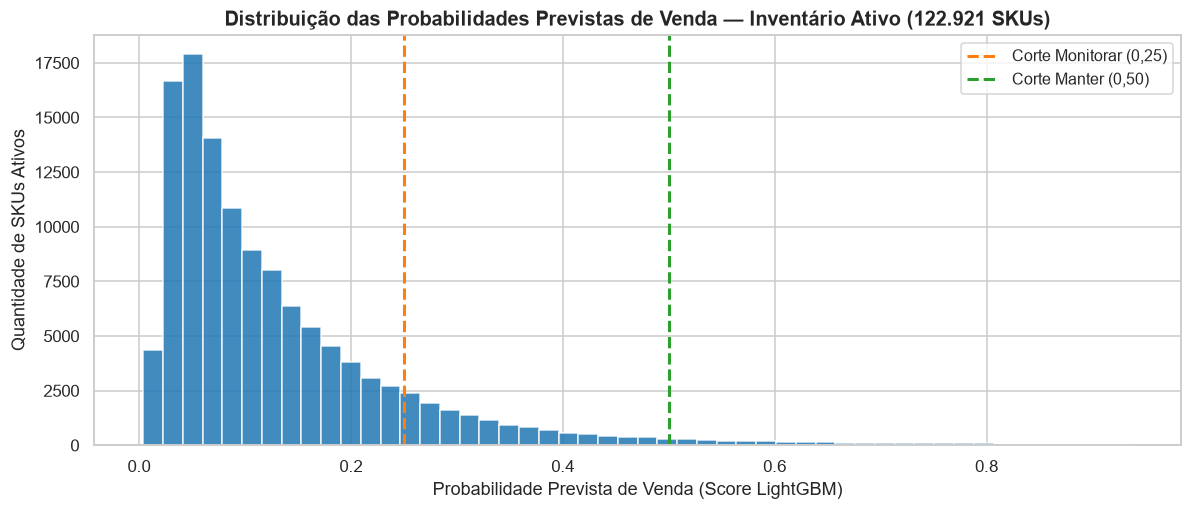

In [8]:
# 1. Pipeline unificado de produção (Clusterização + LightGBM) ajustado em 100% da base histórica
pipeline_producao = Pipeline([
    ("cluster_features", UnsupervisedClusterFeatures(
        cluster_cols=CLUSTER_INPUT_COLS, n_clusters=4, knn_k=10, random_state=RANDOM_STATE
    )),
    ("classifier", lgb.LGBMClassifier(
        n_estimators=350, learning_rate=0.05, num_leaves=31,
        subsample=0.8, colsample_bytree=0.8,
        n_jobs=-1, random_state=RANDOM_STATE, verbose=-1
    ))
])

t0 = time.perf_counter()
pipeline_producao.fit(X_hist, y_hist)
print(f"• Pipeline completo treinado em 100% da base histórica ({len(X_hist):,} SKUs) em {time.perf_counter() - t0:.2f} s")

# Salva o pipeline completo e portável
Path("models").mkdir(exist_ok=True)
model_path = Path("models/inventory_classifier_pipeline.joblib")
joblib.dump(pipeline_producao, model_path, compress=3)
print(f"• Pipeline salvo em: {model_path} ({model_path.stat().st_size / 1024:.1f} KB)")

# 2. Escoragem dos 122.921 SKUs do inventário ativo
scores_ativos = pipeline_producao.predict_proba(X_active)[:, 1]

df_decisao = df_active[["SKU_number", "MarketingType", "ReleaseYear", "PriceReg", "ItemCount", "StrengthFactor"]].copy()
df_decisao["prob_venda"] = np.round(scores_ativos, 4)

def classificar_acao(score):
    if score >= 0.50:
        return "1. Manter (Alta Propensão >= 50%)"
    elif score >= 0.25:
        return "2. Monitorar / Promover (25% a 50%)"
    else:
        return "3. Liquidar / Desinvestir (< 25%)"

df_decisao["recomendacao"] = df_decisao["prob_venda"].apply(classificar_acao)

# Resumo executivo do inventário ativo por faixa de decisão
resumo_ativo = df_decisao.groupby("recomendacao").agg(
    Qtd_SKUs=("SKU_number", "count"),
    Proporcao_perc=("SKU_number", lambda s: round(len(s) / len(df_decisao) * 100, 2)),
    Score_Medio=("prob_venda", "mean"),
    Mediana_PriceReg=("PriceReg", "median"),
    Mediana_ItemCount=("ItemCount", "median")
).round(3)

print("\n=== PLANO DE AÇÃO PARA O INVENTÁRIO ATIVO (122.921 SKUs) ===")
display(resumo_ativo)

# Exportação de artefatos leves (Top 500 manter e resumo executivo) para consumo da área de negócio
Path("outputs").mkdir(exist_ok=True)
resumo_ativo.to_csv("outputs/resumo_decisao_inventario_ativo.csv", encoding="utf-8")
df_decisao.sort_values("prob_venda", ascending=False).head(500).to_csv(
    "outputs/top_500_skus_manter.csv", index=False, encoding="utf-8"
)
df_decisao.sort_values("prob_venda", ascending=True).head(500).to_csv(
    "outputs/top_500_skus_liquidar.csv", index=False, encoding="utf-8"
)
print("• Artefatos exportados em outputs/: resumo_decisao_inventario_ativo.csv, top_500_skus_manter.csv e top_500_skus_liquidar.csv")

# Visualização da distribuição dos scores no inventário ativo
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.hist(df_decisao["prob_venda"], bins=50, color="#1f77b4", edgecolor="white", alpha=0.85)
ax.axvline(0.25, color="#ff7f0e", linestyle="--", lw=2, label="Corte Monitorar (0,25)")
ax.axvline(0.50, color="#2ca02c", linestyle="--", lw=2, label="Corte Manter (0,50)")
ax.set_title("Distribuição das Probabilidades Previstas de Venda — Inventário Ativo (122.921 SKUs)", fontsize=13, fontweight="bold")
ax.set_xlabel("Probabilidade Prevista de Venda (Score LightGBM)")
ax.set_ylabel("Quantidade de SKUs Ativos")
ax.legend(fontsize=10.5)
plt.tight_layout()
plt.show()

---
## 9. Considerações Finais, Limitações dos Dados e Próximos Passos

### Impacto de Negócio Entregue
1. **Foco cirúrgico de capital de giro**: Em vez de gerir 122.921 SKUs da mesma maneira quando historicamente mais de 80% não vendem, o modelo segmenta o inventário em três ações objetivas (**Manter**, **Monitorar/Promover** e **Liquidar/Desinvestir**).
2. **Rigor metodológico sem *Data Leakage***: Toda a etapa de clusterização (`PowerTransformer`, `PCA`, `K-Means`, `GMM` e `KNN`) foi encapsulada em um transformador `scikit-learn` ajustado exclusivamente no treino e validada no holdout de `15.200` SKUs nunca vistos.
3. **Flexibilidade operacional por *Threshold***: A política de corte pode ser calibrada rapidamente entre modo **Conservador** (minimizar estoque parado) e **Agressivo** (evitar ruptura de vendas) conforme o orçamento e custo de armazenagem do trimestre.

### Limitações Críticas do Dataset e Evolução Recomendada em Produção
Uma visão madura de Ciência de Dados também reconhece os limites dos dados disponíveis:
- **Granularidade de snapshot (sem dimensão temporal)**: O dataset informa apenas se o SKU vendeu nos últimos 6 meses (`SoldFlag`), sem a data exata das vendas, sazonalidade mensal ou histórico de rupturas (*stockouts*).
- **Dados recomendados para a V2 em produção**:
  1. Série temporal mensal de vendas por SKU (para modelos de *Demand Forecasting* e *Safety Stock*).
  2. Margem unitária, custo de aquisição e custo de armazenagem por m³ (para substituir *thresholds* fixos por **otimização direta de Lucro Esperado**).
  3. *Lead time* do fornecedor e indicadores de campanhas promocionais ativas.